<table style="width: 100%;">
  <tr>
    <td style="text-align: left; vertical-align: middle;">
        <h1 style="margin: 0;">Deep Learning's Assignment 2</h1>
        <h4 style="margin: 0;">Prof. Bahrak</h4>
        <h4 style="margin: 0;">Authors: Erfan Ahmadi, Mohammad Ali Olama</h4>
        <h4 style="margin: 0;">[Group work]</h4>
    </td>
    <td style="text-align: right; vertical-align: middle;">
      <img src="https://media.porsline.ir/images/1642313491sktwifppujekhvh" alt="CC" width="1000">
    </td>
  </tr>
</table>



In [14]:
from tensorflow import keras
from tensorflow.keras.layers import Dense, Dropout, InputLayer, Flatten
from tensorflow.keras.regularizers import l2
from sklearn.metrics import confusion_matrix
import seaborn as sns
from google.colab import drive
import tensorflow as tf
import os
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import GlobalAveragePooling2D, GlobalMaxPooling2D
from tensorflow.keras.applications import VGG16
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.models import Model
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.callbacks import LearningRateScheduler
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.vgg16 import preprocess_input
from sklearn.metrics import classification_report
import plotly.express as px
import pandas as pd

In [3]:
tf.random.set_seed(42)

# Question2

Mount the Drive and unzip the data

In [4]:
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
# !unzip /content/drive/MyDrive/TEIAS/Deep/HW2/Q2_Dataset.zip -d /content/drive/MyDrive/TEIAS/Deep/HW2/datasets_B/

## Q2.1

There's nothing asked in this section

## Q2.2

### Load the Dataset

In [6]:


dataset_path_test = '/content/drive/MyDrive/TEIAS/Deep/HW2/datasets_B/HW2_Dataset/Test'
dataset_path_train = '/content/drive/MyDrive/TEIAS/Deep/HW2/datasets_B/HW2_Dataset/Train'

batch_size = 1       # Adjust as per your resources
train_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path_train,
    labels='inferred',
    label_mode='binary', # Or 'int', 'binary' depending on your task
    batch_size=batch_size,
    image_size=(224, 224),
    shuffle=True,
)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path_test,
    labels='inferred',
    label_mode='binary',
    batch_size=batch_size,
    image_size=(224, 224),
    shuffle=True,
)





Found 702 files belonging to 2 classes.
Found 100 files belonging to 2 classes.


We resize the images to (224,224,3) images. (It's crucial since VGG16 and RESNET50 receive (224,224,3) images.

### Preprocessing
For the preprocessing step, we decide to use ```imagenet_utils.preprocess_input``` function to prepare the data.
This function will do this(According to documentation):

*will convert the images from RGB to BGR,then will zero-center each color channel withrespect to the ImageNet dataset,without scaling. subtracting mean = [103.939, 116.779, 123.68] from channels.*

In the paper, they split the dataset into train and validation set. The training set consists of 500 images and validdation size is 200.
Since we have shuffled the data when we load from the disk, we just pick the first 200 samples as validation dataset.

In [7]:
# Split the training dataset as mentioned in Figure 1 in papaer
validation_size = 200
validation_data = []
validation_data_label = []
original_train_data = []
original_train_data_label = []
count = 0  # Initialize a counter

for images, labels in train_dataset:  # Iterate through the entire dataset
  if count < validation_size:
    validation_data.append(images)
    validation_data_label.append(labels)
  else:
    original_train_data_label.append(labels)
    original_train_data.append(images)
  count += 1  # Increment the counter

In [8]:
# Load the test data
test_data = []
test_data_label = []

for images, labels in test_dataset:  # Iterate through the entire dataset
    test_data.append(images)
    test_data_label.append(labels)


Convert the data into numpy array for convinience

In [9]:
original_train_data = np.concatenate(original_train_data)
original_train_data_label = np.concatenate(original_train_data_label).flatten()

# Now you have a NumPy array 'original_train_data' and 'original_train_data_label'
print(original_train_data.shape)
print(original_train_data_label.shape)



(502, 224, 224, 3)
(502,)


 Do the same for Validation and Test

In [10]:
validation_data = np.concatenate(validation_data)
validation_data_label = np.concatenate(validation_data_label).flatten()

# Now you have a NumPy array 'validation_data' and 'validation_data_label'
print(validation_data.shape)
print(validation_data_label.shape)


(200, 224, 224, 3)
(200,)


In [11]:
test_data = np.concatenate(test_data)
test_data_label = np.concatenate(test_data_label).flatten()

# test_data = test_data / 255.0

# Now you have a NumPy array 'validation_data' and 'validation_data_label'
print(test_data.shape)
print(test_data_label.shape)



(100, 224, 224, 3)
(100,)


### Some simple EDA


#### 1. Class Distribution Analysis

- **Objective:**  
  Determine if the classes are balanced or if there is a class imbalance issue.
  
- **Methods:**  
  - We have done this in the previous sections on the whole dataset.

---


In [15]:
# Count the occurrences of each class

original_train_data_label_temp = original_train_data_label.astype(int)
class_counts = np.bincount(original_train_data_label_temp)

# Create a DataFrame for Plotly
class_df = pd.DataFrame({'Class': np.arange(len(class_counts)), 'Count': class_counts})


# Create the bar plot using Plotly Express
fig = px.bar(class_df, x='Class', y='Count', title='Distribution of Classes in Labels',
             labels={'Class': 'Class Label', 'Count': 'Number of Samples'})
fig.show()


In [17]:
# Count the occurrences of each class
validation_data_label_temp = validation_data_label.astype(int)
class_counts = np.bincount(validation_data_label_temp)

# Create a DataFrame for Plotly
class_df = pd.DataFrame({'Class': np.arange(len(class_counts)), 'Count': class_counts})


# Create the bar plot using Plotly Express
fig = px.bar(class_df, x='Class', y='Count', title='Distribution of Classes in Labels',
             labels={'Class': 'Class Label', 'Count': 'Number of Samples'})
fig.show()



#### 2. Sample Image Visualization

- **Objective:**  
  Get a visual feel for the images in the dataset and assess their quality and diversity.
  
- **Methods:**  
  - Display a few random samples from each class.
  - Create a grid of images for each category to observe variations in appearance.

---


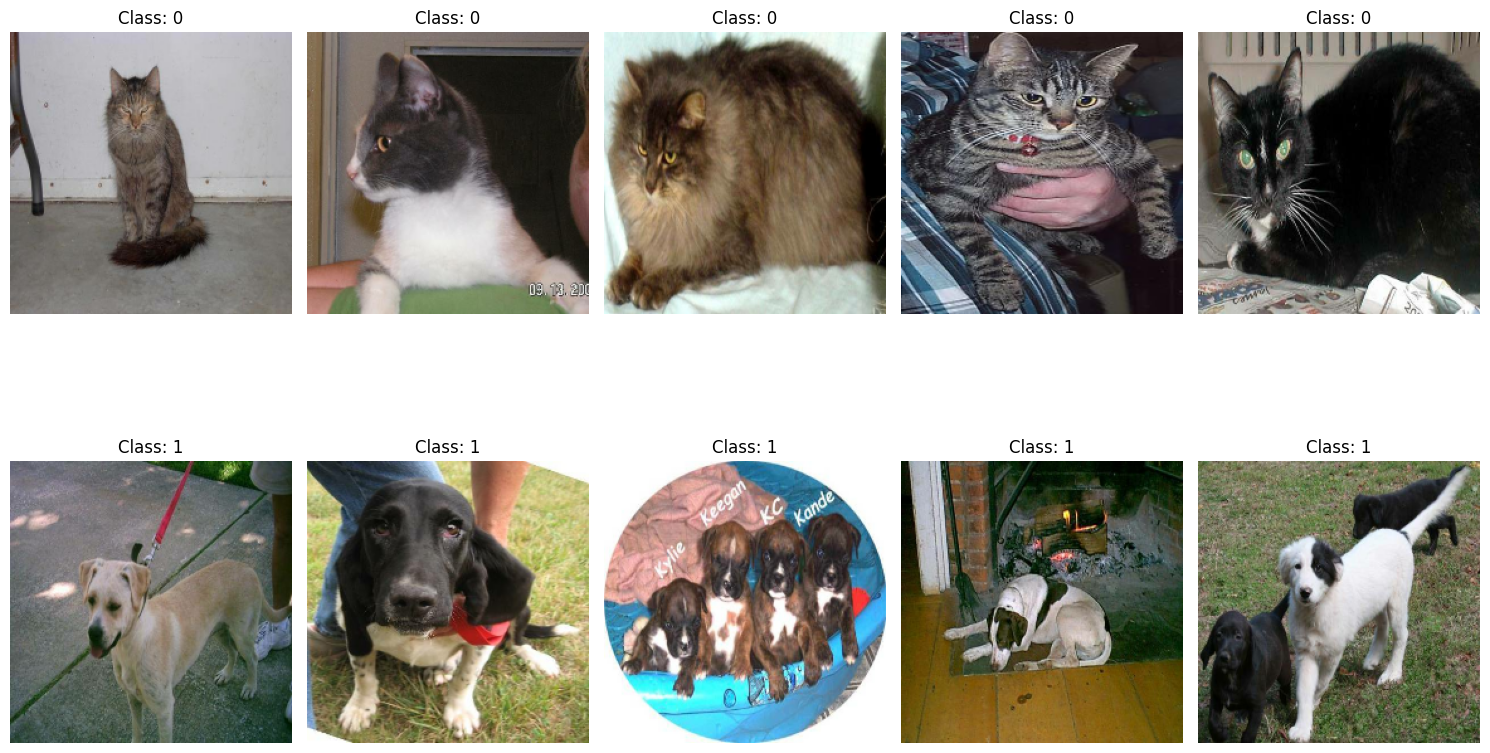

In [18]:
# Number of samples to plot per class
num_samples_per_class = 5

# Unique classes in y_train
unique_classes = np.unique(original_train_data_label_temp)

# Create subplots
fig, axes = plt.subplots(len(unique_classes), num_samples_per_class, figsize=(15, 10))

for class_index, class_label in enumerate(unique_classes):
    class_indices = np.where(original_train_data_label_temp == class_label)[0]
    selected_indices = np.random.choice(class_indices, size=num_samples_per_class, replace=False)

    for i, index in enumerate(selected_indices):
      axes[class_index, i].imshow(original_train_data[index] / 255.)
      axes[class_index, i].set_title(f"Class: {class_label}")
      axes[class_index, i].axis('off')

plt.tight_layout()
plt.show()



#### 3. Pixel Intensity Distribution

- **Objective:**  
  Evaluate the brightness, contrast, and overall pixel intensity distribution.
  
- **Methods:**  
  - Plot histograms of pixel intensities for a random subset of images.
  - Analyze the distribution to decide on normalization strategies.

---

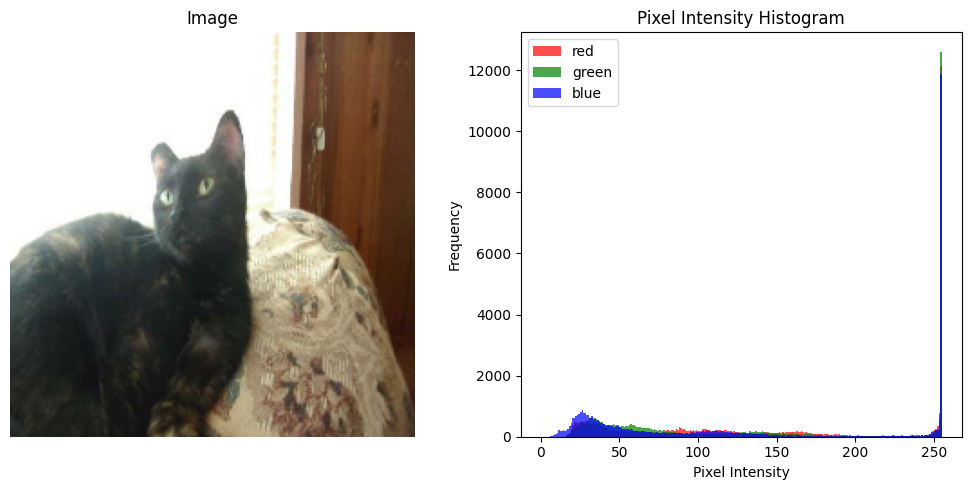

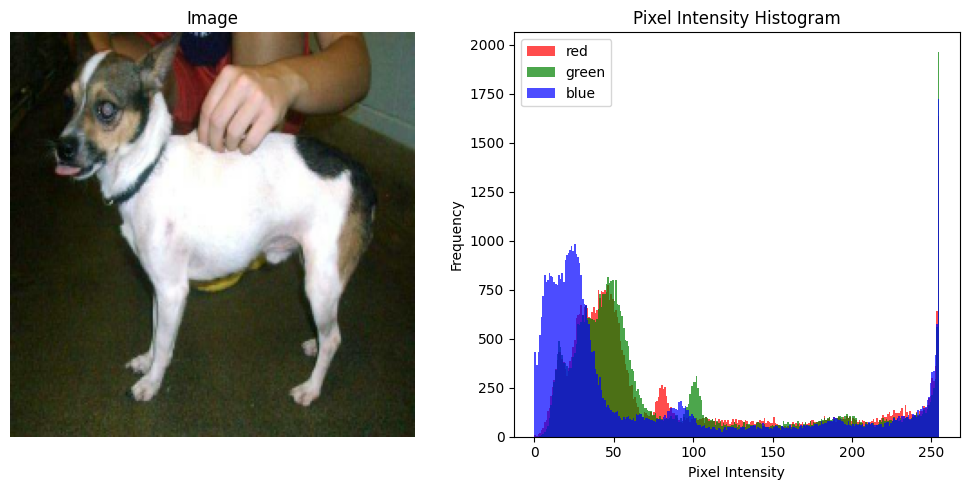

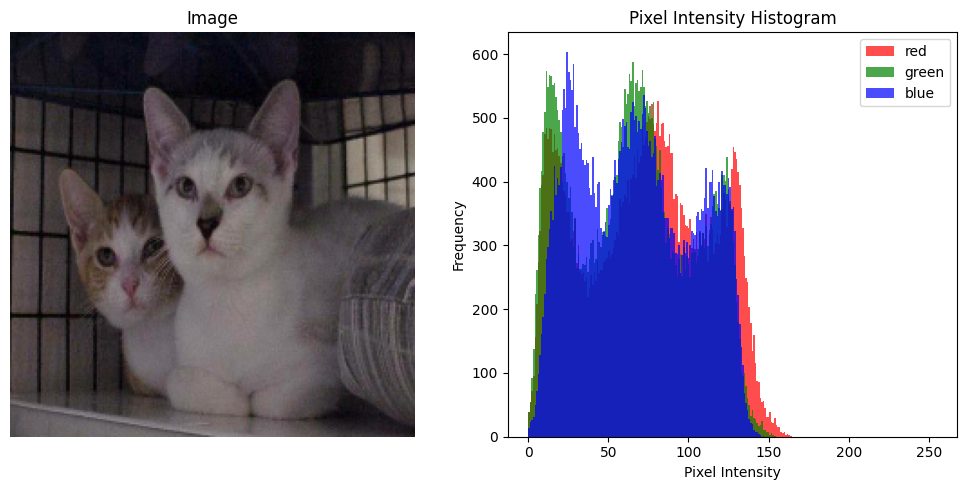

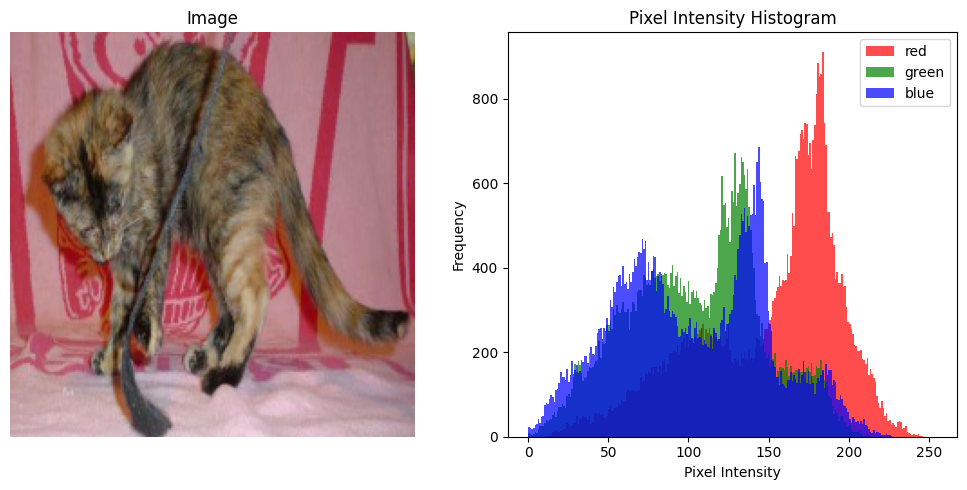

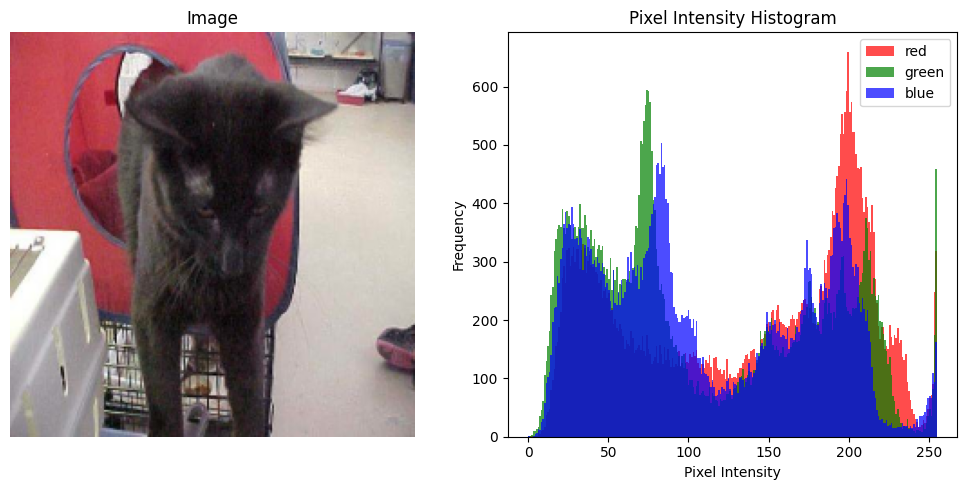

In [29]:

import matplotlib.pyplot as plt

def plot_image_and_histogram(image):
  """Plots an image and its pixel intensity histogram."""

  plt.figure(figsize=(10, 5))

  # Plot the image
  plt.subplot(1, 2, 1)
  plt.imshow(image / 255.)  # Normalize pixel values to 0-1 for display
  plt.title("Image")
  plt.axis('off')

  # Plot the histogram
  plt.subplot(1, 2, 2)
  colors = ['red', 'green', 'blue']
  for i, color in enumerate(colors):
    plt.hist(image[:, :, i].flatten(), bins=256, range=(0, 255), alpha=0.7, color=color, label=color)
  plt.title("Pixel Intensity Histogram")
  plt.xlabel("Pixel Intensity")
  plt.ylabel("Frequency")
  plt.legend()

  plt.tight_layout()
  plt.show()


num_images_to_plot = 5  # Adjust as needed
for i in range(min(num_images_to_plot, len(original_train_data))):
  plot_image_and_histogram(original_train_data[i])


### Augumentation
We use ImageDataGenrator from Keras to augment the dataset.(The same as original paper)

*In this work, image data generator class of Keras deep learning framework is used for augmenting
training samples. The number of training samples generated by data augmentation technique is very high
when compared with training samples without the data augmentation when the number of epochs is high. In
case of data augmentation, different series of training samples are generated during every epoch whereas,
without the data augmentation, the same set of training samples are used during every epoch. Total number
of training samples generated by the Image data generator for N epochs is calculated as given in*

**How Keras Handles Data Augmentation with `ImageDataGenerator`**

Keras uses `ImageDataGenerator` to **dynamically create new training samples** by applying random transformations to existing images during training. Instead of physically creating and saving new images, it **augments data on the fly** in memory each time a batch is fed to the model.

This means:
- Each epoch may see slightly different versions of the same image.
- The model is exposed to a wider variety of data without increasing dataset size.
- It helps improve generalization and reduce overfitting.

Augmented samples are generated **in real-time**, making the process efficient and scalable for large datasets.


**ImageGenerator for VGG models**:

In [ ]:
# Acording to the paper the Min_Batch_size is 10 so we set this
MIN_BATCH_SIZE = 10

# Create an ImageDataGenerator for data augmentation
datagen_vgg = ImageDataGenerator(
    horizontal_flip=True,
    rotation_range=30,
    zoom_range=[0.75, 1.25],
    fill_mode='nearest' # Or other fill modes like 'reflect', 'wrap'
)

original_train_datagen_vgg = ImageDataGenerator()
validation_datagen_vgg = ImageDataGenerator()

# Create the augmented dataset
augmented_train_dataset_vgg = datagen_vgg.flow(
    original_train_data/255.0,
    original_train_data_label,
    batch_size=MIN_BATCH_SIZE,
    shuffle=True # Keep shuffle True
)

original_train_dataset_vgg = original_train_datagen_vgg.flow(
    original_train_data/255.0,
    original_train_data_label,
    batch_size=MIN_BATCH_SIZE,
    shuffle=True # Keep shuffle True
)

#Create the same for the validation dataset
validation_dataset_vgg = validation_datagen_vgg.flow(
    validation_data/255.0,
    validation_data_label,
    batch_size=MIN_BATCH_SIZE,
    shuffle=False # Keep shuffle True
)


In [ ]:
test_datagen_vgg = ImageDataGenerator()
test_dataset_vgg = test_datagen_vgg.flow(
    test_data/255.0,
    test_data_label,
    shuffle=False # Keep shuffle True
)

**ImageGenerator for Resnet50 models**:

In [ ]:

# Create an ImageDataGenerator for data augmentation, applying preprocessing
datagen_resnet = ImageDataGenerator(
    preprocessing_function=preprocess_input,  # Apply ResNet50 preprocessing
    horizontal_flip=True,
    rotation_range=30,
    zoom_range=[0.75, 1.25],
    fill_mode='nearest'
)

original_train_datagen_resnet = ImageDataGenerator(preprocessing_function=preprocess_input)
validation_datagen_resnet = ImageDataGenerator(preprocessing_function=preprocess_input)

# Create the augmented dataset
augmented_train_dataset_resnet = datagen_resnet.flow(
    original_train_data,
    original_train_data_label,
    batch_size=MIN_BATCH_SIZE,
    shuffle=True # Keep shuffle True
)

original_train_dataset_resnet = original_train_datagen_resnet.flow(
    original_train_data,
    original_train_data_label,
    batch_size=MIN_BATCH_SIZE,
    shuffle=True # Keep shuffle True
)

#Create the same for the validation dataset
validation_dataset_resnet = validation_datagen_resnet.flow(
    validation_data,
    validation_data_label,
    batch_size=MIN_BATCH_SIZE,
    shuffle=False # Keep shuffle True
)



In [ ]:
test_datagen_resnet = ImageDataGenerator(preprocessing_function=preprocess_input)
test_dataset_resnet = test_datagen_resnet.flow(
    test_data,
    test_data_label,
    shuffle=False # Keep shuffle True
)

The total number of generated images will be
$$ M = \text{Batch_Size} \times \text{Iterations} \times N $$
Where
$ N = \text{number of epochs}$

According to the parameters in the paper:

$$ M = 10 \times 50 \times 50 = 25000 $$

## Q2.3

We first write 3 utility functions for training, evaluating, and plotting. As these functions are independent to the type of the model, we write them generally.

In [ ]:
def finetune(model, train_dataset, validation_dataset , layers , LEARNING_RATE = 0.001):

  #Phase 1
  # Freeze all of the convolution layers for transferring what has been learned and train the model
  # As it is already freezed we just trin the model
  # Set the hyperparameters

  LR_DECAY = 0.002
  MOMENTUM = 0.9
  NO_EPOCHS = 50

  # LR schedule for decay, since automatic decay is depricated from keras optimizers.
  def lr_schedule(epoch):
    return LEARNING_RATE / (1 + LR_DECAY * epoch)

  #Now train the model using Mini_Batch Gradient Descent

  optimizer = tf.keras.optimizers.SGD(learning_rate=LEARNING_RATE, momentum=MOMENTUM)
  model.compile(optimizer=optimizer, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
  history = model.fit(train_dataset, epochs=10, validation_data=validation_dataset, verbose=1 , callbacks=[LearningRateScheduler(lr_schedule)])

  print("Phase 1 Completed")

  #Phase 2
  #Unfreeze the last Conv_Block and train again
  for layer in layers:
    layer.trainable = True

  #Retrain the model based on new structure

  optimizer = tf.keras.optimizers.SGD(learning_rate=LEARNING_RATE, momentum=MOMENTUM)
  model.compile(optimizer=optimizer, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
  history2 = model.fit(train_dataset, epochs=NO_EPOCHS, validation_data=validation_dataset, verbose=1, callbacks=[LearningRateScheduler(lr_schedule)])

  print("Phase 2 Completed")
  return history, history2

#### Report on the `finetune` Function

The `finetune` function implements a two-phase fine-tuning process for a given deep learning model, specifically designed for image classification tasks.  This process leverages transfer learning, utilizing pre-trained weights to improve performance on a new dataset.

**Phase 1: Initial Fine-tuning**

1. **Freezing Convolutional Layers:**  All convolutional layers in the input `model` are initially frozen. This prevents the pre-trained weights from being updated during this phase.  This step ensures the model retains the knowledge gained from the original training dataset (e.g., ImageNet).

2. **Training with Modified Layers:** Only the newly added layers (typically classification layers) are trained.  The model learns to adapt its final classification output based on the input dataset.

3. **Hyperparameters:**
    - `LEARNING_RATE`:  The initial learning rate for the optimizer. **(The original initial Learning Rate in the paper was a bit large therefore we used a more appropriate one)**
    - `LR_DECAY`: A learning rate decay factor applied during training.
    - `MOMENTUM`: The momentum parameter used in the SGD optimizer.
    - `NO_EPOCHS`: The total number of epochs for this training phase.  The provided code uses 10 epochs.
4. **Optimizer:** Stochastic Gradient Descent (SGD) is used with the defined learning rate and momentum.

5. **Learning Rate Schedule:**  A learning rate scheduler dynamically adjusts the learning rate during training, further refining the optimization process.

6. **Training Process:**  The model is trained for a specified number of epochs using the `fit` method. The `train_dataset` is used for training, and the `validation_dataset` is used for validation. The `LearningRateScheduler` callback ensures that the learning rate is adjusted per epoch as defined by the `lr_schedule` function.

**Phase 2: Fine-tuning Deeper Layers**

1. **Unfreezing Layers:** A specified set of layers provided by the `layers` argument are unfrozen. This allows for further adaptation of the model to the target dataset.

2. **Retraining the Model:** The model is retrained with the unfrozen layers. This fine-tunes the model to the new dataset, leveraging the learned features from the pre-trained layers while adapting them to the specific characteristics of the data.

3. **Hyperparameters & Training:** The same optimizer, learning rate schedule, and training method as Phase 1 are used.  However, the number of epochs is now determined by `NO_EPOCHS`, which is set to 50 in the code.


**Return Values**

The function returns the training history objects from both phases (`history`, `history2`).  These objects contain information about the loss, accuracy, and other metrics during training and validation.


**Overall Function Purpose**

The `finetune` function provides a structured approach to fine-tune a pre-trained model on a new image classification dataset. It balances preserving the general features learned by the pre-trained model with adapting those features to the new data, improving the overall accuracy and performance of the model on the target task.

  This function is for evaluating the final results
  As wanted in the question we also calculate and plot the loss besides the accuracy in the paper

In [ ]:
def evaluate(model , test_dataset , test_data_label):
  # Evaluate the model on the test dataset
  loss, accuracy = model.evaluate(test_dataset)
  print(f"Test Loss: {loss}")
  print(f"Test Accuracy: {accuracy}")

  # Get predictions
  predictions = model.predict(test_dataset)
  predicted_labels = np.argmax(predictions, axis=1)
  report = classification_report(test_data_label, predicted_labels)
  print(report)

  # Create and display the confusion matrix
  cm = confusion_matrix(test_data_label, predicted_labels)
  plt.figure(figsize=(8, 6))
  sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
  plt.xlabel('Predicted')
  plt.ylabel('True')
  plt.title('Confusion Matrix')
  plt.show()



And the last one for plotting the histories

In [ ]:
def plot_histories(history1, history2, title1="Augmented Data", title2="Original Data"):
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))

    # Plot training & validation accuracy values for the first history
    axes[0, 0].plot(history1.history['accuracy'])
    axes[0, 0].plot(history1.history['val_accuracy'])
    axes[0, 0].set_title(f'Model accuracy - {title1}')
    axes[0, 0].set_ylabel('Accuracy')
    axes[0, 0].set_xlabel('Epoch')
    axes[0, 0].legend(['Train', 'Validation'], loc='upper left')


    # Plot training & validation loss values for the first history
    axes[0, 1].plot(history1.history['loss'])
    axes[0, 1].plot(history1.history['val_loss'])
    axes[0, 1].set_title(f'Model loss - {title1}')
    axes[0, 1].set_ylabel('Loss')
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].legend(['Train', 'Validation'], loc='upper left')

    # Plot training & validation accuracy values for the second history
    axes[1, 0].plot(history2.history['accuracy'])
    axes[1, 0].plot(history2.history['val_accuracy'])
    axes[1, 0].set_title(f'Model accuracy - {title2}')
    axes[1, 0].set_ylabel('Accuracy')
    axes[1, 0].set_xlabel('Epoch')
    axes[1, 0].legend(['Train', 'Validation'], loc='upper left')

    # Plot training & validation loss values for the second history
    axes[1, 1].plot(history2.history['loss'])
    axes[1, 1].plot(history2.history['val_loss'])
    axes[1, 1].set_title(f'Model loss - {title2}')
    axes[1, 1].set_ylabel('Loss')
    axes[1, 1].set_xlabel('Epoch')
    axes[1, 1].legend(['Train', 'Validation'], loc='upper left')

    plt.tight_layout()
    plt.show()

#Concatenate histories and plot them
def concatenate_and_plot(history1, history2, Label_Plot=""):
    # Concatenate histories (you might need to adjust this part depending on the structure of your history objects)
    combined_history = {}
    for key in history1.history:
        combined_history[key] = history1.history[key] + history2.history[key]


    plt.figure(figsize=(10, 5))
    plt.plot(combined_history['accuracy'])
    plt.plot(combined_history['val_accuracy'])
    plt.title('Model accuracy (Combined) for ' + Label_Plot)
    plt.ylabel('Accuracy')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')
    plt.show()

    plt.figure(figsize=(10, 5))
    plt.plot(combined_history['loss'])
    plt.plot(combined_history['val_loss'])
    plt.title('Model loss (Combined) for ' + Label_Plot)
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')
    plt.show()




Now we can start creating the models and finetune them

### VGG16

#### VGG16 with augumented data

In [ ]:


def create_vgg_model():
  base_vgg = VGG16(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

  for layer in base_vgg.layers:
      layer.trainable = False


  x = Flatten()(base_vgg.output)
  # Dense layer with 1024 units: (25088*1024 + 1024) = 25,691,136 parameters
  x = Dense(1024, activation='relu')(x)
  # Output layer for 2 classes: (1024*2 + 2) = 2050 parameters
  predictions = Dense(2, activation='softmax')(x)

  # Total FC parameters: 25,691,136 + 2050 = 25,693,186
  vgg_model = Model(inputs=base_vgg.input, outputs=predictions)
  return vgg_model

vgg_model1 = create_vgg_model()   # used for augumented dataset


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


if we unfreeze the last conv block:

In [ ]:
for layer in vgg_model1.layers[-7:]:
    layer.trainable = True

In [ ]:
vgg_model1.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │    25,691,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │         2,050 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,407,874 (154.14 MB)

 Trainable params: 32,772,610 (125.02 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

This is exactly what we wanted according to the paper. Notice that we should freeze the last conv block in the first phase of training, and then unfreeze in the second phase!


Convert this model back to the previous state

In [ ]:
vgg_model1 = create_vgg_model()

In [ ]:
vgg_model1.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1024)           │    25,691,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │         2,050 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,407,874 (154.14 MB)

 Trainable params: 25,693,186 (98.01 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [ ]:
history1_vgg_aug, history2_vgg_aug = finetune(vgg_model1, augmented_train_dataset_vgg, validation_dataset_vgg, vgg_model1.layers[-7:])

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 19s 226ms/step - accuracy: 0.5347 - loss: 1.1792 - val_accuracy: 0.7750 - val_loss: 0.5188 - learning_rate: 0.0010
Epoch 2/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 7s 141ms/step - accuracy: 0.7017 - loss: 0.5422 - val_accuracy: 0.8650 - val_loss: 0.3520 - learning_rate: 9.9800e-04
Epoch 3/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 9s 171ms/step - accuracy: 0.8019 - loss: 0.4116 - val_accuracy: 0.8700 - val_loss: 0.3044 - learning_rate: 9.9602e-04
Epoch 4/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 8s 149ms/step - accuracy: 0.7888 - loss: 0.4311 - val_accuracy: 0.7600 - val_loss: 0.5234 - learning_rate: 9.9404e-04
Epoch 5/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 8s 151ms/step - accuracy: 0.8465 - loss: 0.3402 - val_accuracy: 0.8500 - val_loss: 0.3379 - learning_rate: 9.9206e-04
Epoch 6/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 9s 169ms/step - accuracy: 0.8569 - loss: 0.3303 - val_accuracy: 0.8500 - val_loss: 0.3188 - learning_rate: 9.9010e-04
Epoch 7/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 7s 144ms/step - accuracy: 0.8

4/4 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 0.9263 - loss: 0.1414
Test Loss: 0.14958065748214722
Test Accuracy: 0.9200000166893005
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 379ms/step
              precision    recall  f1-score   support

         0.0       0.89      0.96      0.92        50
         1.0       0.96      0.88      0.92        50

    accuracy                           0.92       100
   macro avg       0.92      0.92      0.92       100
weighted avg       0.92      0.92      0.92       100



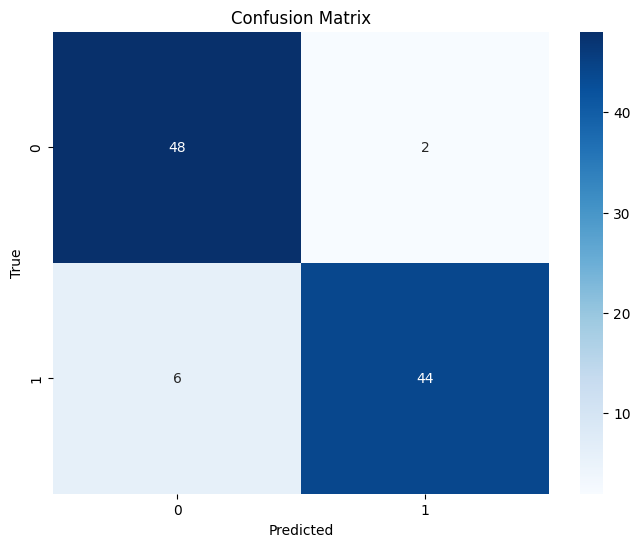

In [ ]:
evaluate(vgg_model1, test_dataset_vgg , test_data_label)

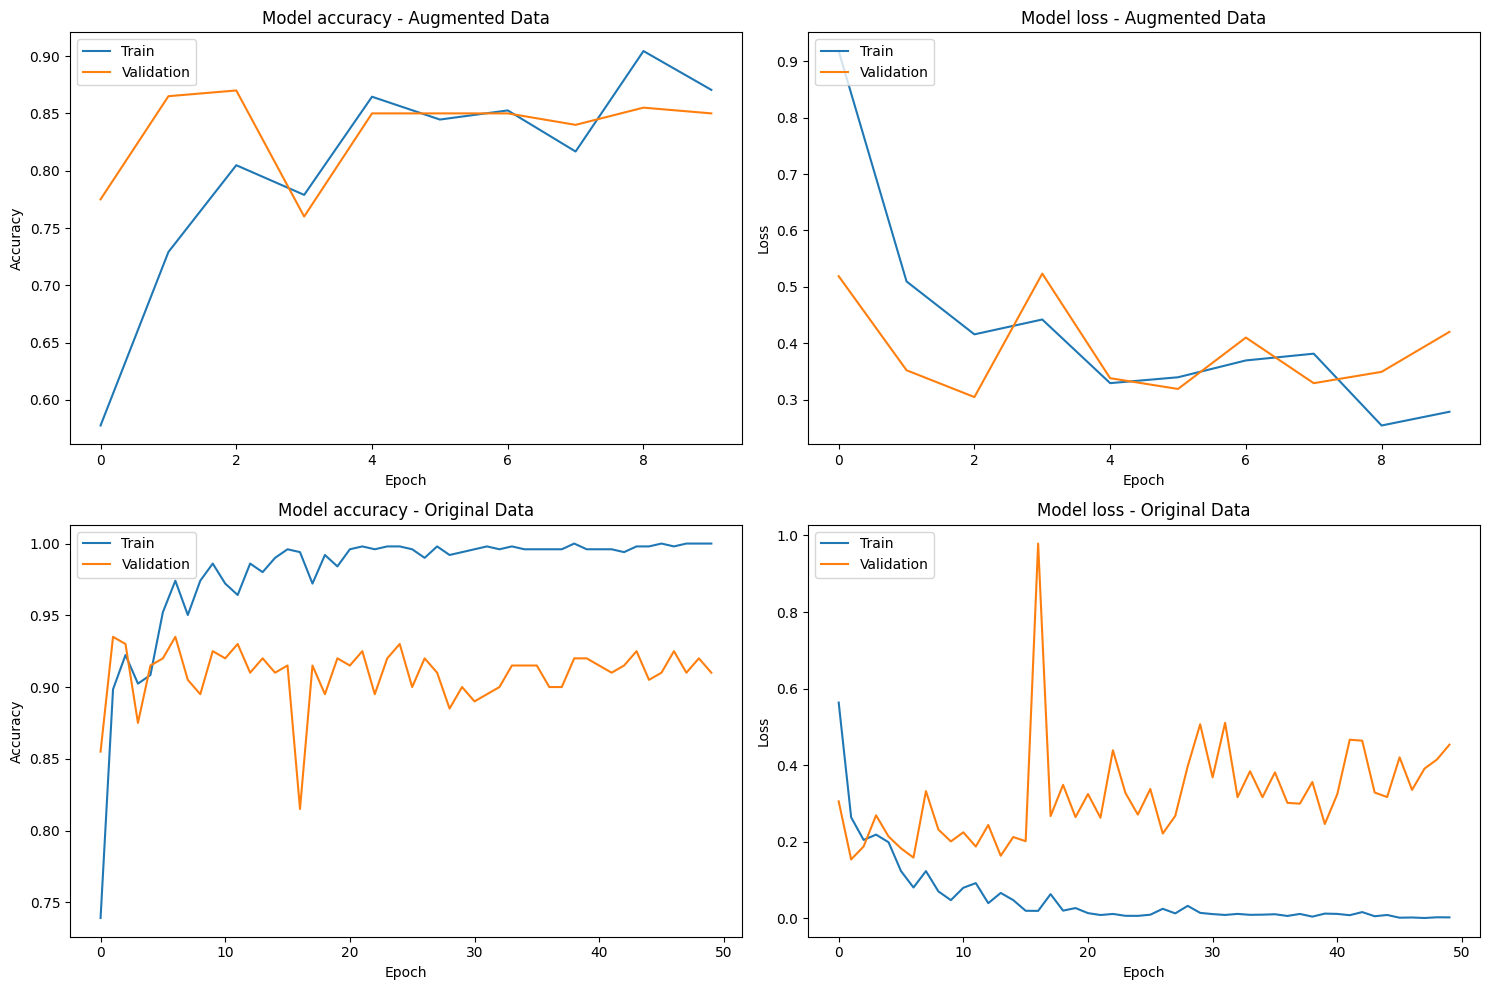

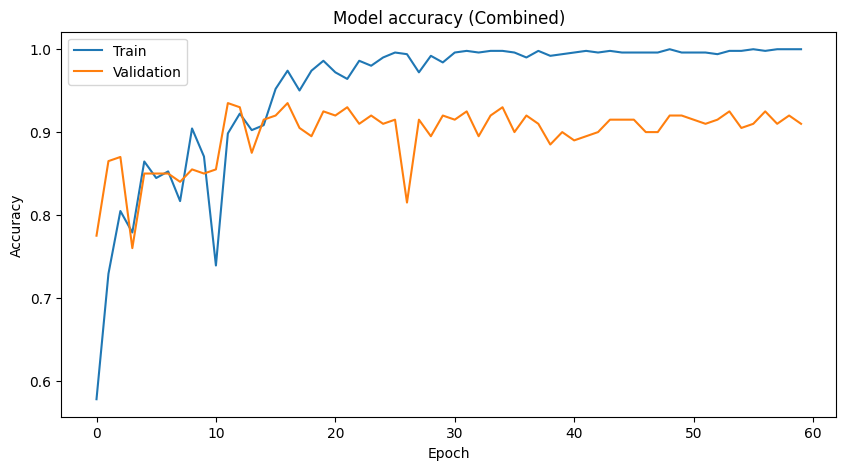

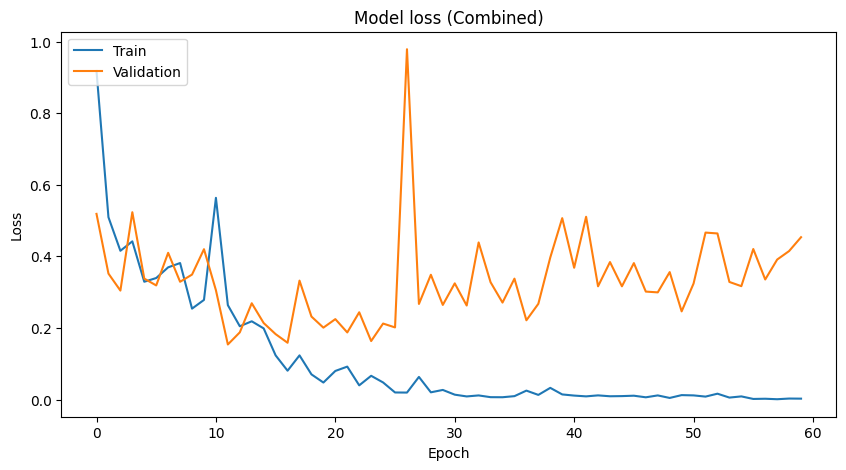

In [ ]:
plot_histories(history1_vgg_aug, history2_vgg_aug)
concatenate_and_plot(history1_vgg_aug, history2_vgg_aug)

#### VGG16 with original data

In [ ]:
vgg_model2 = create_vgg_model()   # used for original dataset.

In [ ]:
# we just pass another dataset which is not augmented!
history1_vgg_org, history2_vgg_org = finetune(vgg_model2, original_train_dataset_vgg, validation_dataset_vgg, vgg_model1.layers[-7:])

Epoch 1/10


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


51/51 ━━━━━━━━━━━━━━━━━━━━ 7s 114ms/step - accuracy: 0.6071 - loss: 0.7691 - val_accuracy: 0.8500 - val_loss: 0.3477 - learning_rate: 0.0010
Epoch 2/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 91ms/step - accuracy: 0.8817 - loss: 0.2562 - val_accuracy: 0.8700 - val_loss: 0.2911 - learning_rate: 9.9800e-04
Epoch 3/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 91ms/step - accuracy: 0.9403 - loss: 0.1523 - val_accuracy: 0.7200 - val_loss: 0.6740 - learning_rate: 9.9602e-04
Epoch 4/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 91ms/step - accuracy: 0.8882 - loss: 0.2538 - val_accuracy: 0.8650 - val_loss: 0.3128 - learning_rate: 9.9404e-04
Epoch 5/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 93ms/step - accuracy: 0.9867 - loss: 0.0648 - val_accuracy: 0.8750 - val_loss: 0.2914 - learning_rate: 9.9206e-04
Epoch 6/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 93ms/step - accuracy: 0.9880 - loss: 0.0535 - val_accuracy: 0.8750 - val_loss: 0.3099 - learning_rate: 9.9010e-04
Epoch 7/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 93ms/step - accuracy: 0.9995 - loss: 0.0308

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 224ms/step - accuracy: 0.8864 - loss: 0.4602
Test Loss: 0.48560917377471924
Test Accuracy: 0.8799999952316284
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 345ms/step
              precision    recall  f1-score   support

         0.0       0.87      0.90      0.88        50
         1.0       0.90      0.86      0.88        50

    accuracy                           0.88       100
   macro avg       0.88      0.88      0.88       100
weighted avg       0.88      0.88      0.88       100



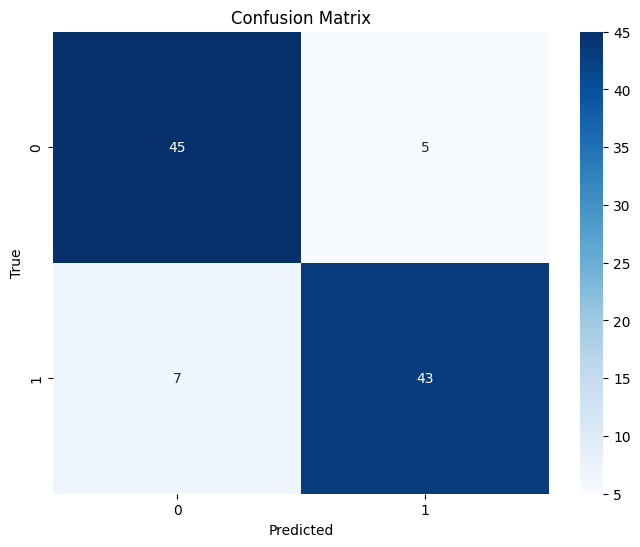

In [ ]:
evaluate(vgg_model2, test_dataset_vgg , test_data_label)

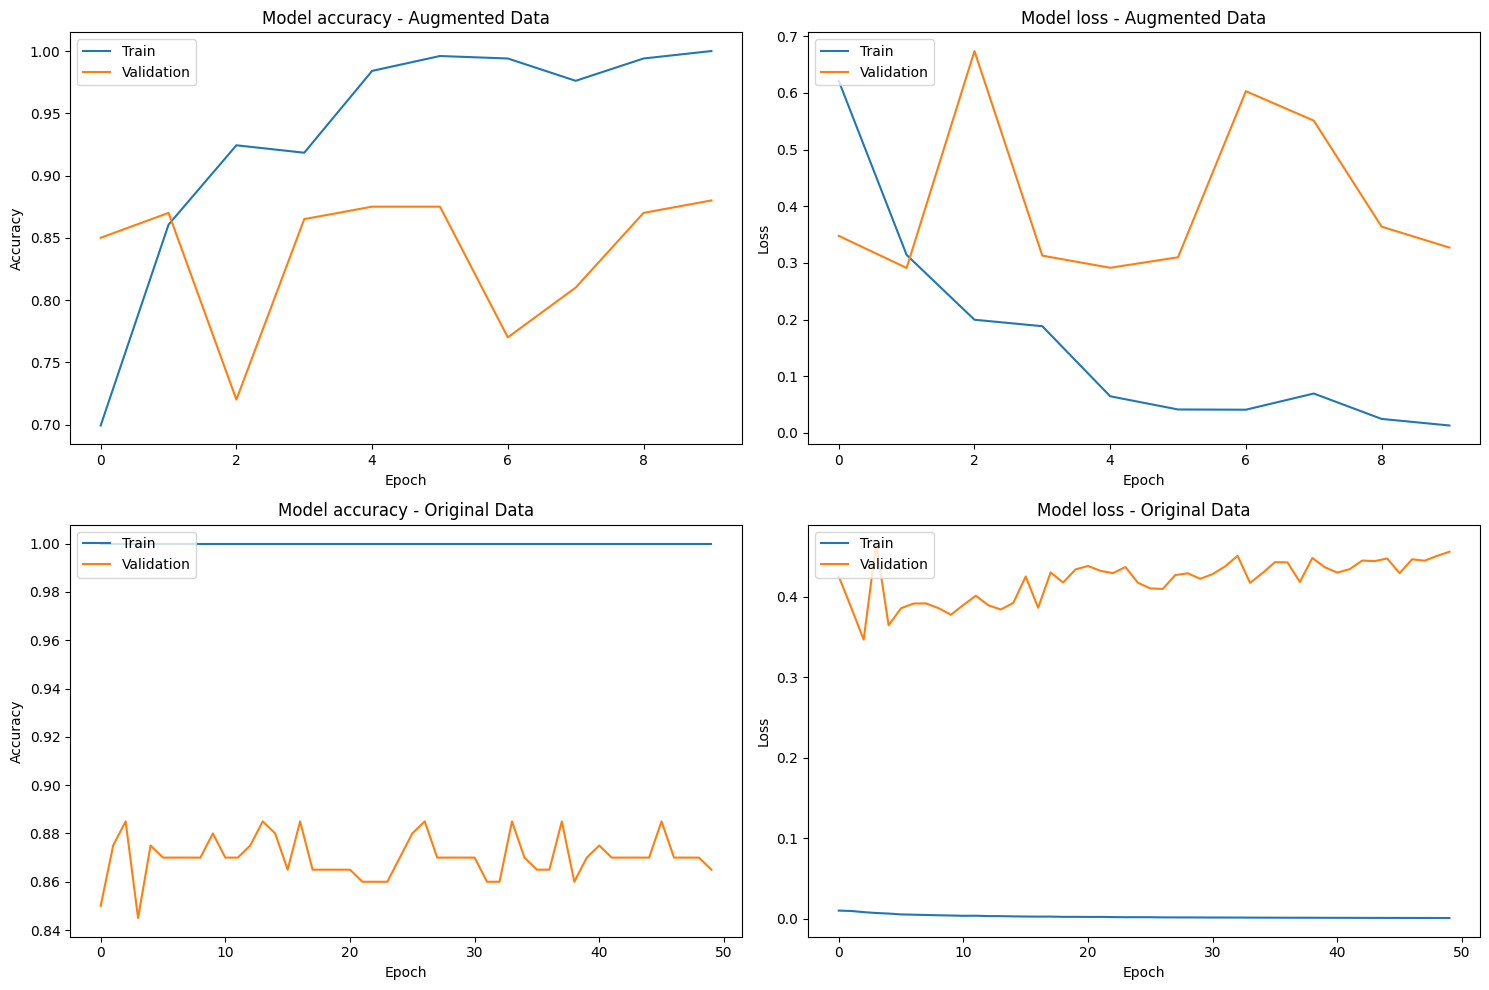

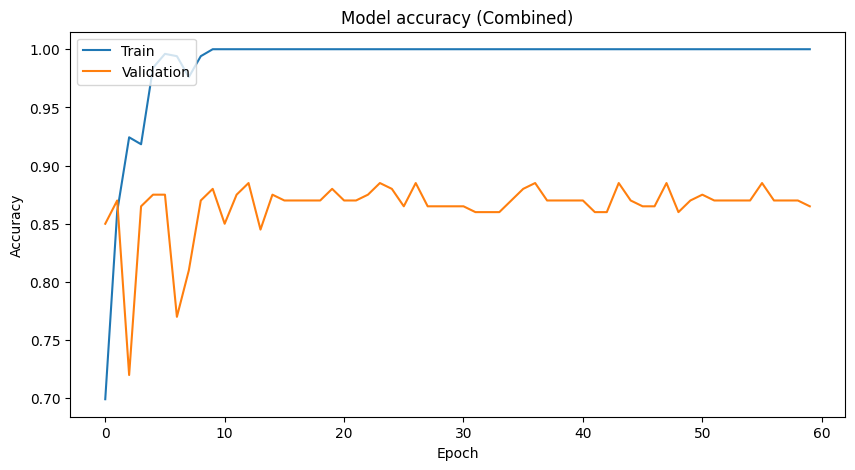

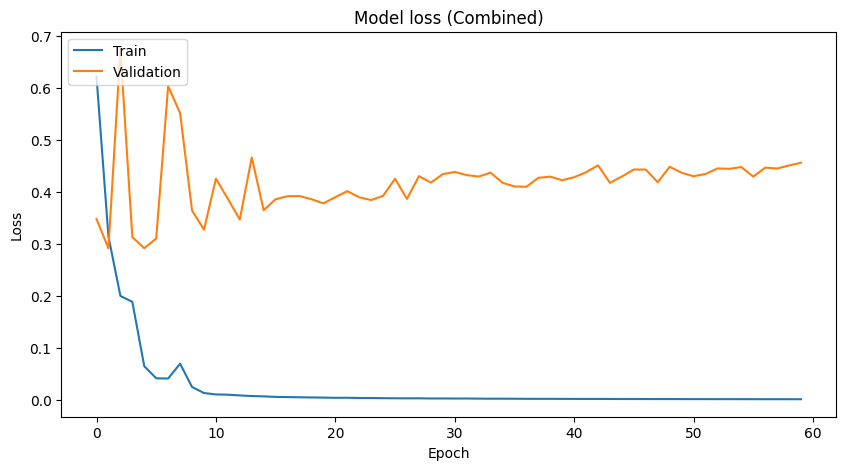

In [ ]:
plot_histories(history1_vgg_org, history2_vgg_org)
concatenate_and_plot(history1_vgg_org, history2_vgg_org)

As you can see exactly the same as the paper, When we used augmentation we didn't face the problem of overfitting. But when ewe didn't use the augmented data here the plot shows sign of overfitting

### Resnet50

Now it's time to do the same for Resnet50.

#### Resnet50 with augmented data

In [ ]:
def create_resnet_model():
  base_resnet = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
  for layer in base_resnet.layers:
      layer.trainable = False


  x = base_resnet.output
  x = GlobalMaxPooling2D()(x)  # Add the average pooling layer
  predictions = Dense(2, activation='softmax')(x)


  resnet_model = Model(inputs=base_resnet.input, outputs=predictions)

  return resnet_model




In [ ]:
resnet_model1 = create_resnet_model()
for layer in resnet_model1.layers[-6:]:
    layer.trainable = True
resnet_model1.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer_3[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 23,591,810 (90.00 MB)

 Trainable params: 1,058,818 (4.04 MB)

 Non-trainable params: 22,532,992 (85.96 MB)

In [ ]:
resnet_model1 = create_resnet_model()

In [ ]:
history1_res_aug, history2_res_aug = finetune(resnet_model1, augmented_train_dataset_resnet, validation_dataset_resnet, resnet_model1.layers[-6:] , LEARNING_RATE = 0.00001)

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 25s 276ms/step - accuracy: 0.5404 - loss: 3.0167 - val_accuracy: 0.8000 - val_loss: 1.0269 - learning_rate: 1.0000e-05
Epoch 2/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 8s 153ms/step - accuracy: 0.8309 - loss: 0.8507 - val_accuracy: 0.9050 - val_loss: 0.5474 - learning_rate: 9.9800e-06
Epoch 3/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 6s 125ms/step - accuracy: 0.9271 - loss: 0.3153 - val_accuracy: 0.9100 - val_loss: 0.4443 - learning_rate: 9.9602e-06
Epoch 4/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 8s 152ms/step - accuracy: 0.9122 - loss: 0.4657 - val_accuracy: 0.9100 - val_loss: 0.5100 - learning_rate: 9.9404e-06
Epoch 5/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 6s 124ms/step - accuracy: 0.9480 - loss: 0.3318 - val_accuracy: 0.9300 - val_loss: 0.2929 - learning_rate: 9.9206e-06
Epoch 6/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 8s 152ms/step - accuracy: 0.9412 - loss: 0.2288 - val_accuracy: 0.9200 - val_loss: 0.3611 - learning_rate: 9.9010e-06
Epoch 7/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 6s 124ms/step - accuracy:

4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 876ms/step - accuracy: 0.9745 - loss: 0.0625
Test Loss: 0.09858029335737228
Test Accuracy: 0.9700000286102295


3/4 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step

4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step
              precision    recall  f1-score   support

         0.0       0.94      1.00      0.97        50
         1.0       1.00      0.94      0.97        50

    accuracy                           0.97       100
   macro avg       0.97      0.97      0.97       100
weighted avg       0.97      0.97      0.97       100



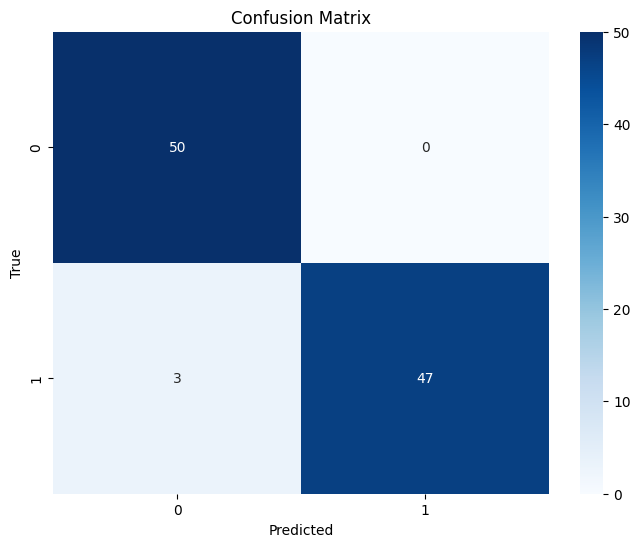

In [ ]:
evaluate(resnet_model1, test_dataset_resnet , test_data_label)

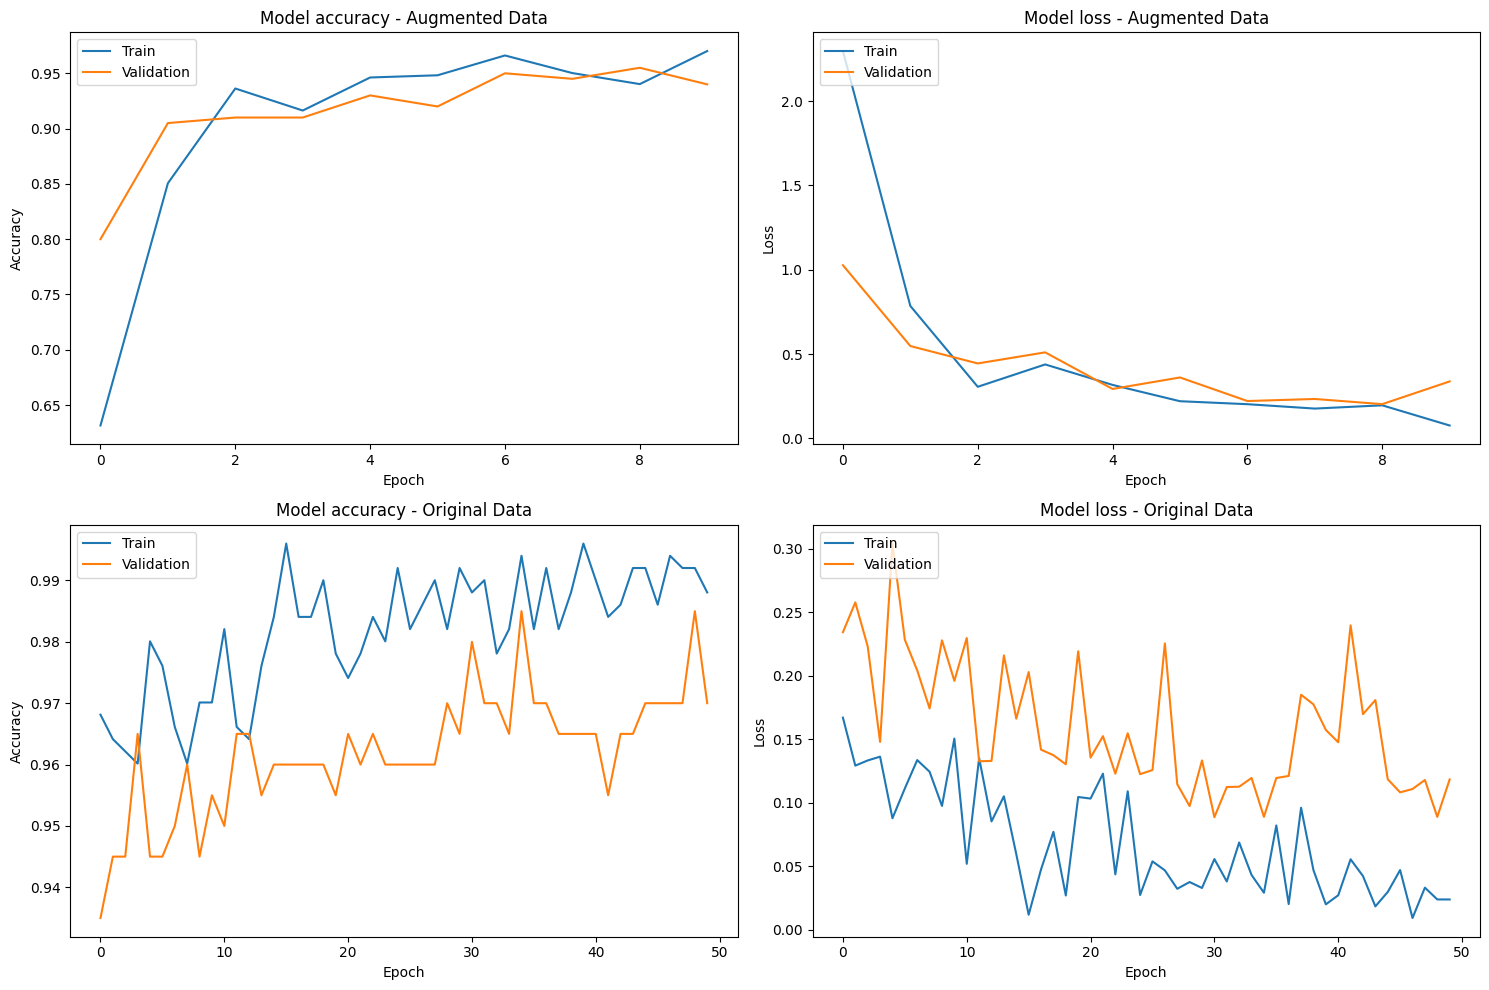

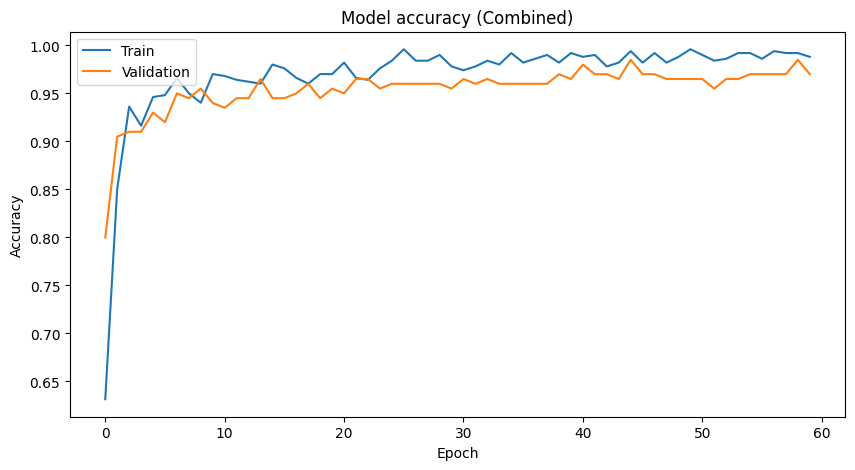

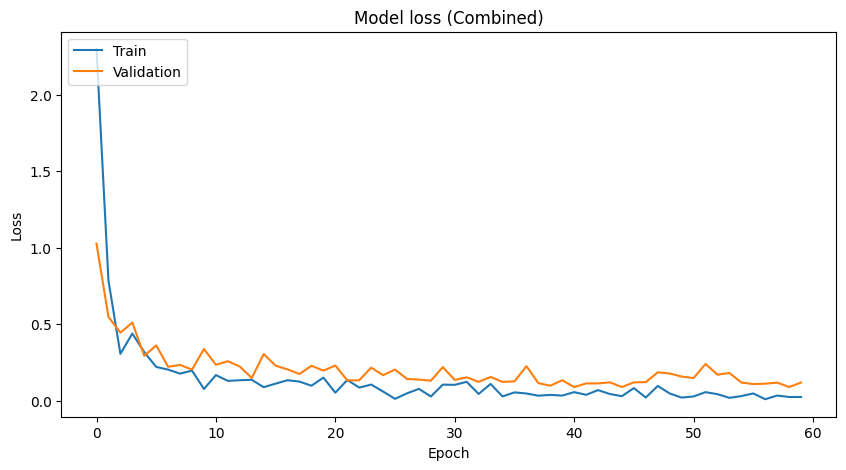

In [ ]:
plot_histories(history1_res_aug, history2_res_aug)
concatenate_and_plot(history1_res_aug, history2_res_aug)

#### Resnet50 with original data

In [ ]:
resnet_model2 = create_resnet_model()

In [ ]:
# we just pass the original dataset without augmentation!
history1_res_org, history2_res_org = finetune(resnet_model2, original_train_dataset_resnet, validation_dataset_resnet, resnet_model2.layers[-6:] , LEARNING_RATE = 0.00001)

Epoch 1/10


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


51/51 ━━━━━━━━━━━━━━━━━━━━ 20s 219ms/step - accuracy: 0.4619 - loss: 5.1613 - val_accuracy: 0.8400 - val_loss: 0.8003 - learning_rate: 1.0000e-05
Epoch 2/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - accuracy: 0.8460 - loss: 0.8422 - val_accuracy: 0.9350 - val_loss: 0.4736 - learning_rate: 9.9800e-06
Epoch 3/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.9161 - loss: 0.4176 - val_accuracy: 0.9700 - val_loss: 0.3067 - learning_rate: 9.9602e-06
Epoch 4/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 3s 43ms/step - accuracy: 0.9326 - loss: 0.2842 - val_accuracy: 0.9700 - val_loss: 0.3241 - learning_rate: 9.9404e-06
Epoch 5/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 3s 57ms/step - accuracy: 0.9608 - loss: 0.1571 - val_accuracy: 0.9700 - val_loss: 0.2851 - learning_rate: 9.9206e-06
Epoch 6/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - accuracy: 0.9733 - loss: 0.1300 - val_accuracy: 0.9750 - val_loss: 0.2722 - learning_rate: 9.9010e-06
Epoch 7/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.9653 - loss: 0

4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 507ms/step - accuracy: 0.9818 - loss: 0.0947
Test Loss: 0.1530245840549469
Test Accuracy: 0.9700000286102295
4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step
              precision    recall  f1-score   support

         0.0       0.98      0.96      0.97        50
         1.0       0.96      0.98      0.97        50

    accuracy                           0.97       100
   macro avg       0.97      0.97      0.97       100
weighted avg       0.97      0.97      0.97       100



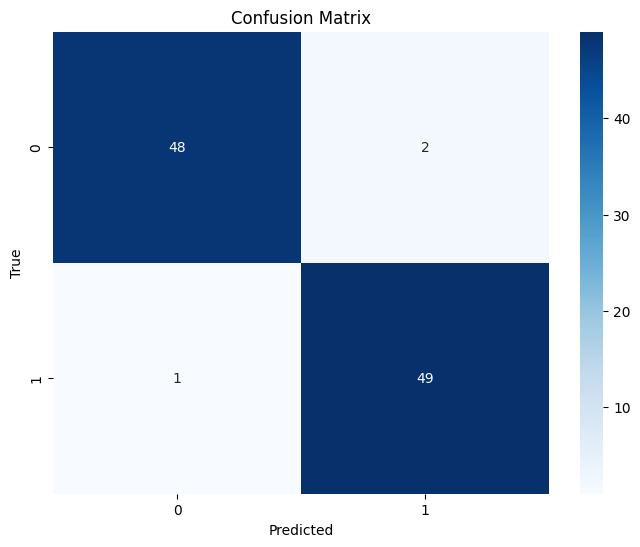

In [ ]:
evaluate(resnet_model2, test_dataset_resnet, test_data_label)

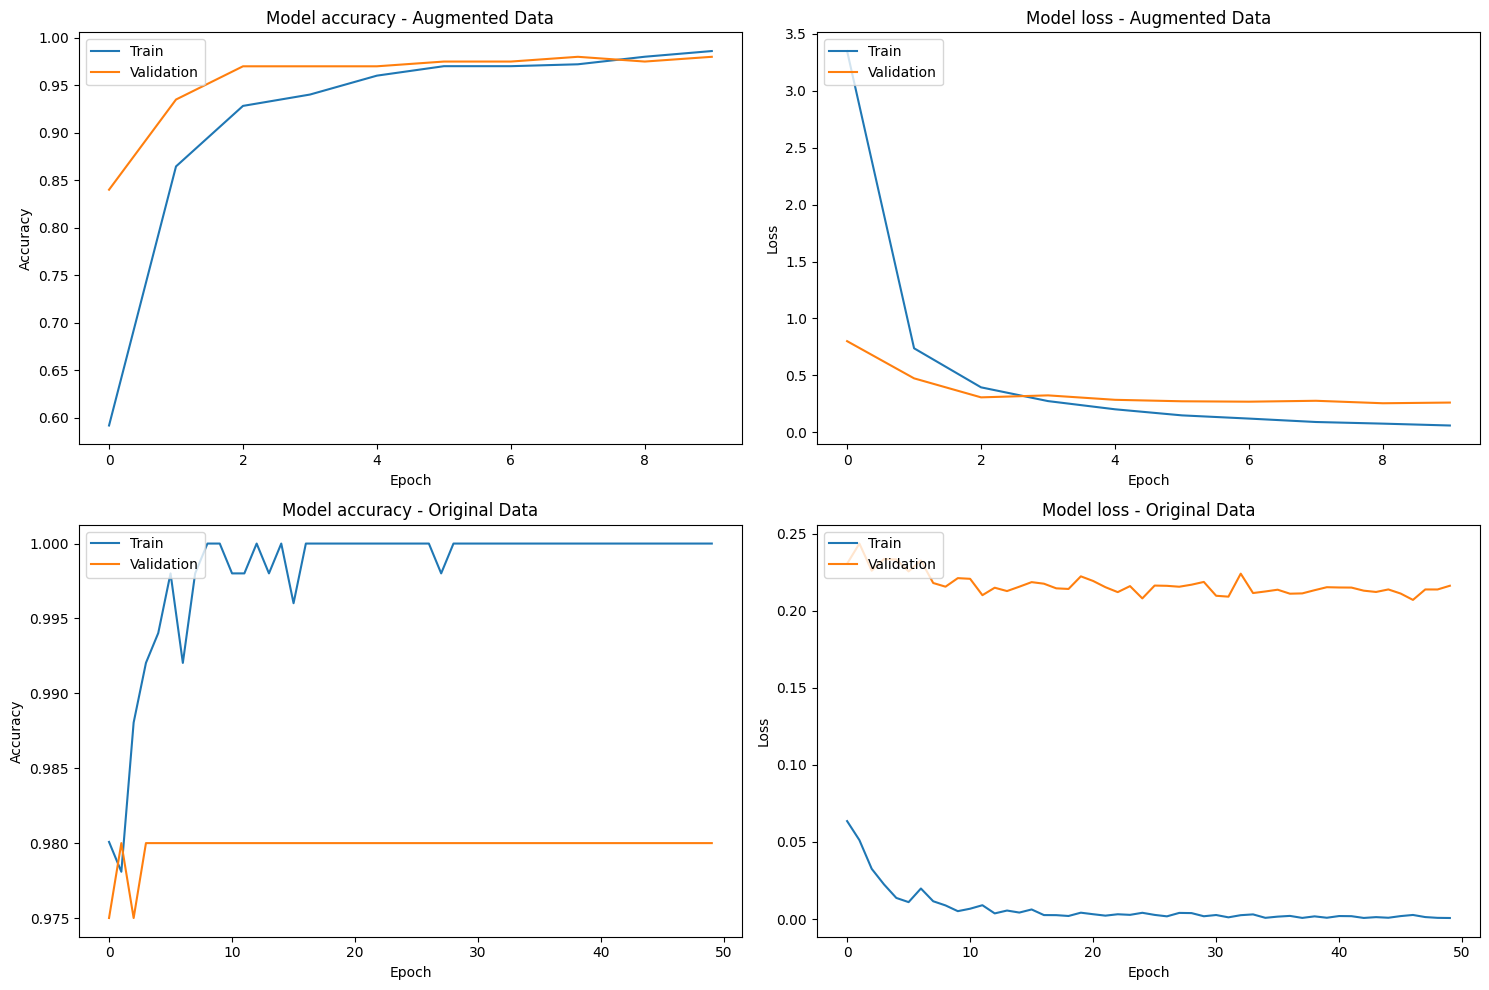

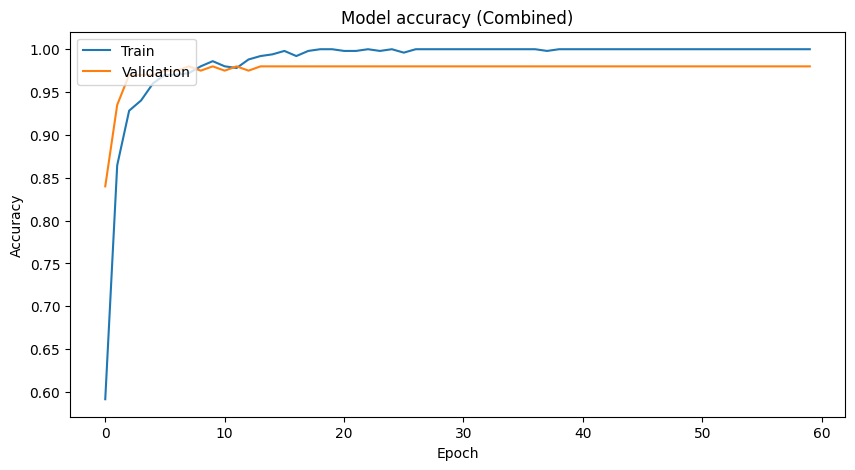

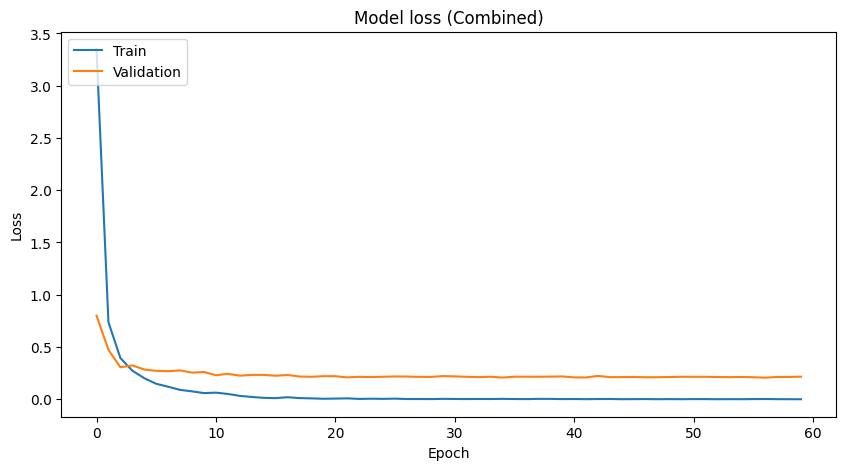

In [ ]:
plot_histories(history1_res_org, history2_res_org)
concatenate_and_plot(history1_res_org, history2_res_org)

## Q2.4


### Evaluatation
we plot loss and accuracy for all models:

<Figure size 1200x800 with 0 Axes>

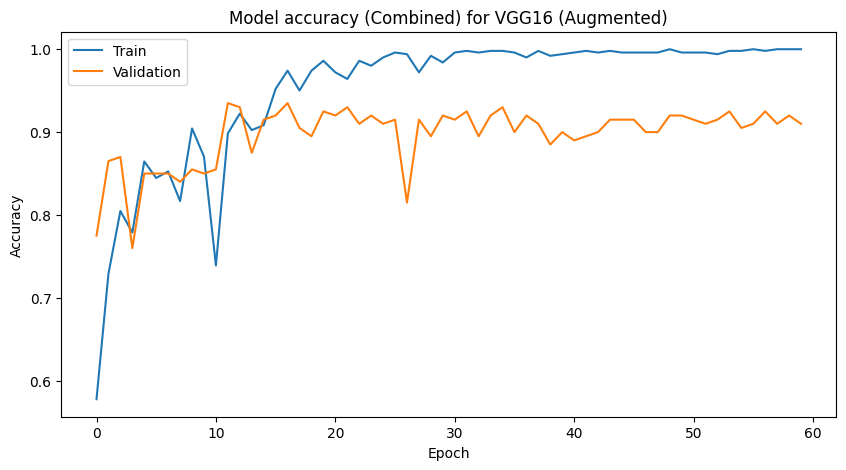

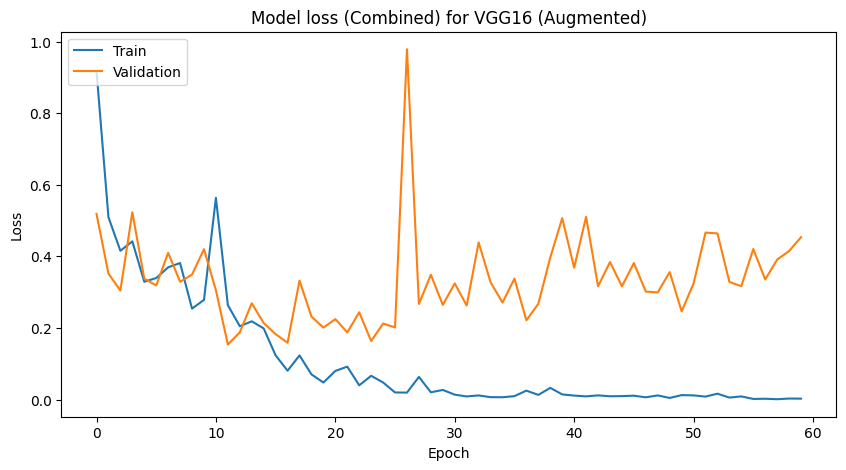

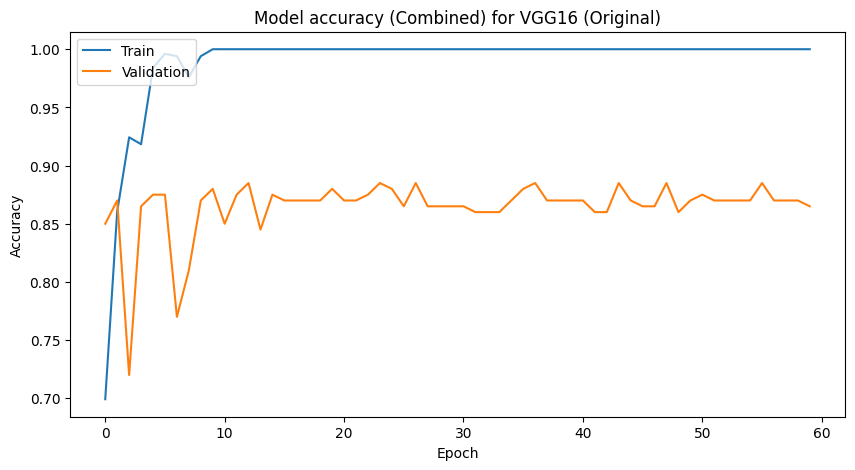

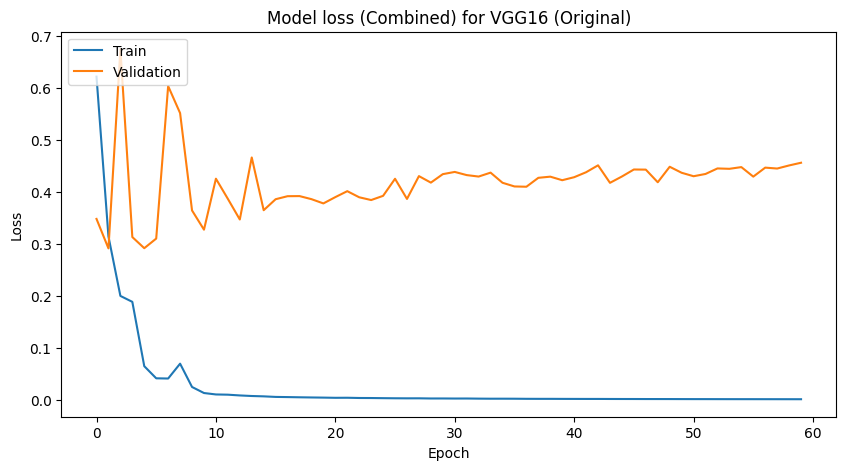

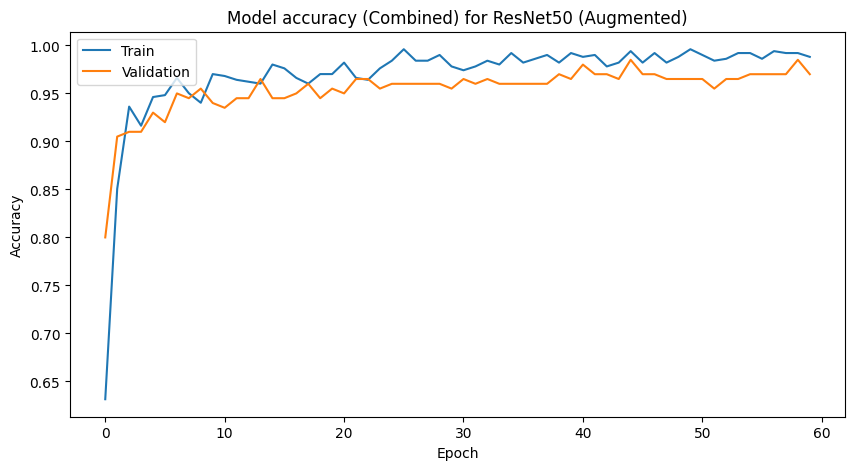

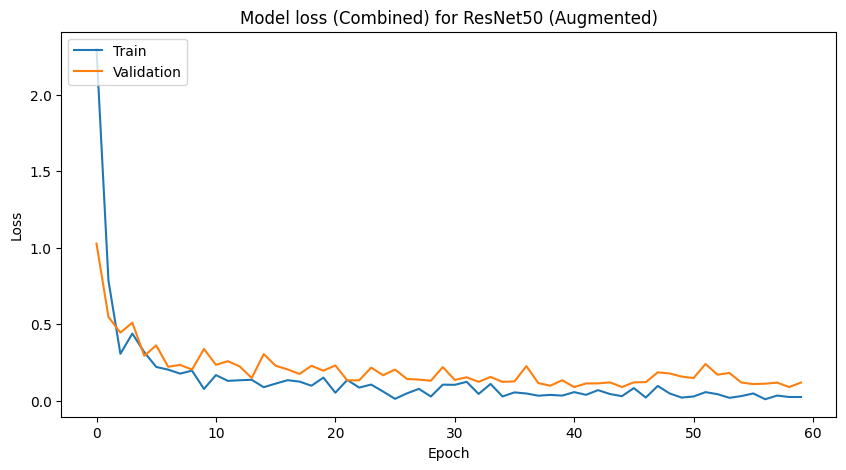

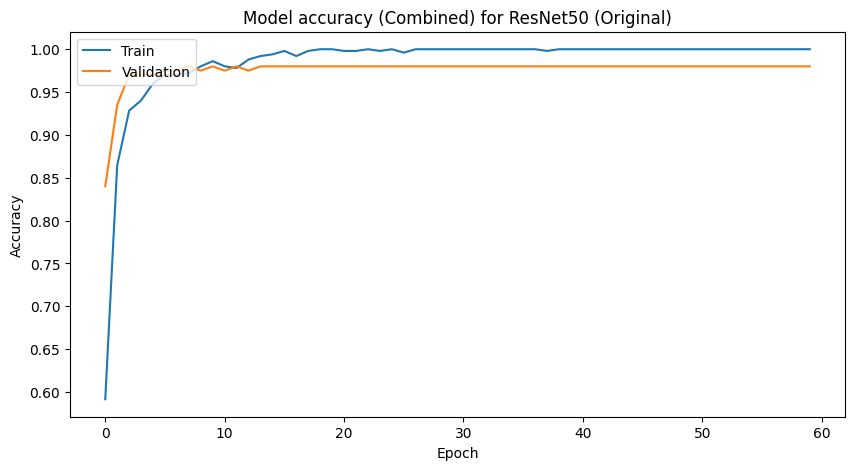

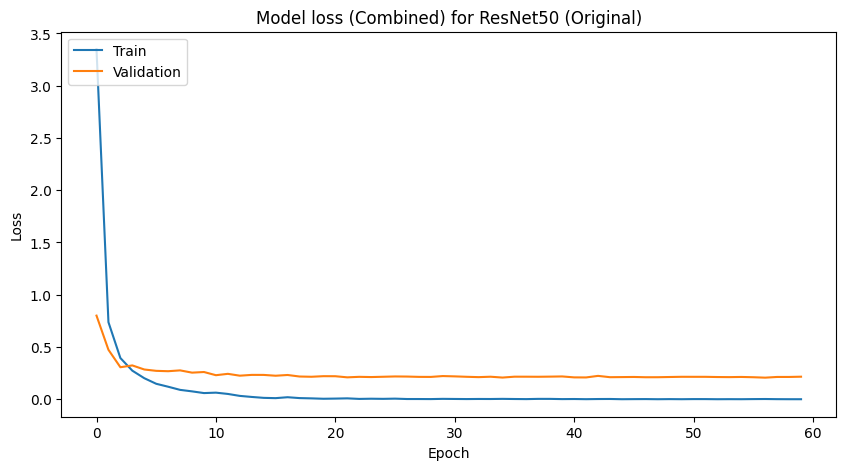

In [ ]:

import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))

# Plot VGG16 (augmented) accuracy
concatenate_and_plot(history1_vgg_aug, history2_vgg_aug, Label_Plot='VGG16 (Augmented)')

# Plot VGG16 (original) accuracy
concatenate_and_plot(history1_vgg_org, history2_vgg_org, Label_Plot='VGG16 (Original)')

# Plot ResNet50 (augmented) accuracy
concatenate_and_plot(history1_res_aug, history2_res_aug, Label_Plot='ResNet50 (Augmented)')

# Plot ResNet50 (original) accuracy
concatenate_and_plot(history1_res_org, history2_res_org, Label_Plot='ResNet50 (Original)')

In [ ]:

import numpy as np
import pandas as pd

def evaluate_models(models, model_names, test_datasets, test_labels):
    results = []
    for i, model in enumerate(models):
        loss, accuracy = model.evaluate(test_datasets[i])
        predictions = model.predict(test_datasets[i])
        predicted_labels = np.argmax(predictions, axis=1)
        report = classification_report(test_labels[i], predicted_labels, output_dict=True)

        results.append({
            'Model': model_names[i],
            'Test Loss': loss,
            'Test Accuracy': accuracy,
            'Precision': report['macro avg']['precision'],
            'Recall': report['macro avg']['recall'],
            'F1-score': report['macro avg']['f1-score']
        })

    return pd.DataFrame(results)


models = [vgg_model1, vgg_model2, resnet_model1, resnet_model2]
model_names = ["vgg_model_aug", "vgg_model_org", "resnet_model_aug", "resnet_model_org"]
test_datasets = [test_dataset_vgg, test_dataset_vgg, test_dataset_resnet, test_dataset_resnet]
test_labels = [test_data_label, test_data_label, test_data_label, test_data_label]


model_results_df = evaluate_models(models, model_names, test_datasets, test_labels)
print(model_results_df)


4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 124ms/step - accuracy: 0.9263 - loss: 0.1414
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 118ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 122ms/step - accuracy: 0.8864 - loss: 0.4602
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 125ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.9745 - loss: 0.0625
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.9818 - loss: 0.0947
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
              Model  Test Loss  Test Accuracy  Precision  Recall  F1-score
0     vgg_model_aug   0.149581           0.92   0.922705    0.92  0.919872
1     vgg_model_org   0.485609           0.88   0.880609    0.88  0.879952
2  resnet_model_aug   0.098580           0.97   0.971698    0.97  0.969973
3  resnet_model_org   0.153025           0.97   0.970188    0.97  0.969997


### Conclusion
Fine-tuning pre-trained models like ResNet50 and VGG16, coupled with data augmentation, leads to superior performance in image classification tasks compared to building CNNs from scratch. This approach is particularly advantageous when the target task aligns with the pre-trained models' original purpose. While optimization techniques can enhance model training, data augmentation plays a crucial role in mitigating overfitting by expanding the training dataset and improving generalization. Researchers employed the Keras framework to fine-tune these pre-trained models on a custom dataset based on Kaggle's CAT vs DOG images, utilizing mini-batch gradient descent with adaptive learning rates and categorical cross-entropy loss for optimization and evaluation. The results demonstrated that models trained with augmented data achieved higher accuracy and reduced loss. However, a key limitation is that modifying the architecture of these pre-trained models could significantly impact their effectiveness. This emphasizes the importance of carefully considering architectural changes when adapting these models for new tasks.

### Performance Difference between VGG16 and ResNet50

**ResNet50** generally outperforms **VGG16** in terms of accuracy on this dataset and similar image classification tasks.

**Reasons for the Difference:**

* **ResNet50's Architecture:** ResNet50's architecture incorporates **skip connections (residual blocks)** which address the vanishing gradient problem, enabling training of deeper networks. This leads to better feature extraction and overall performance.
* **VGG16's Complexity:** VGG16 is known for its **large number of parameters**, making it computationally more expensive and potentially prone to overfitting. While data augmentation can help alleviate this, ResNet50's design inherently tackles the complexity issue.
* **Data Augmentation:** Both models benefit significantly from data augmentation, mitigating overfitting and improving generalization. The experiment showed data augmentation enhanced accuracy more for VGG16 than ResNet50, possibly because VGG16 is more susceptible to overfitting with limited data.
* **Learning Rate and Optimization:** The hyperparameters used, such as learning rate and optimization technique (mini-batch gradient descent with adaptive learning rates), play a role in the final performance. While both models were trained with similar hyperparameters, their inherent architectural differences can lead to varying optimization paths.

## Analysis of Model Performance with and without Data Augmentation

This report analyzes the performance of VGG16 and ResNet50 models trained on a binary image classification task (CAT vs. DOG), both with and without data augmentation.  The analysis is based on training and validation accuracy/loss plots, confusion matrices, and classification reports.

### Key Observations

* **Impact of Data Augmentation:** Data augmentation significantly improves model performance, particularly for VGG16.  Without augmentation, VGG16 shows signs of overfitting (high training accuracy but lower validation accuracy), whereas the augmented VGG16 demonstrates better generalization. ResNet50 benefits from augmentation as well, but the overfitting issue is less pronounced compared to VGG16.

* **Model Comparison:** ResNet50 generally outperforms VGG16 across both augmented and original datasets.  This is likely due to its residual architecture, which helps alleviate the vanishing gradient problem and enables the training of deeper networks.  ResNet50's superior feature extraction capabilities contribute to its higher accuracy.

* **Overfitting:** The models trained without data augmentation exhibit more overfitting, especially VGG16.  This is evident in the training and validation accuracy/loss curves, where the gap between the two metrics is greater for the non-augmented models. Data augmentation increases the diversity of the training data, which helps prevent the models from memorizing the training set and improve generalization.

* **Confusion Matrices:** Confusion matrices provide a visualization of the model's classification performance across classes.  A well-performing model will have high diagonal values, indicating correct predictions. The matrices in the original code provide a more detailed visual overview of model prediction accuracy.

* **Quantitative Results:** The classification reports provide metrics such as precision, recall, and F1-score for each class.  These metrics offer a more precise measure of model performance and offer a way to compare the models based on these metrics.  The generated dataframe provides a clear numerical comparison of all models.


### Detailed Analysis per Model

**VGG16:**

* **Augmented Data:** The model demonstrates good generalization with high accuracy and low loss on both training and validation sets. The consistent performance indicates that data augmentation effectively mitigates overfitting.
* **Original Data:** Clear overfitting is observed, with training accuracy significantly higher than validation accuracy. This suggests the model is memorizing the training data rather than learning generalizable features.


**ResNet50:**

* **Augmented Data:**  Shows better performance overall compared to VGG16. While there is still improvement in performance with augmentation, the effect is not as pronounced as with VGG16.
* **Original Data:** Similar to VGG16, the model exhibits overfitting, although to a lesser degree.


### Performance Differences between VGG16 and ResNet50

ResNet50 consistently outperforms VGG16 due to its architectural advantages:

* **Residual Connections:** The skip connections of ResNet50 effectively address the vanishing gradient problem, allowing for deeper networks that extract more sophisticated features.

* **Computational Efficiency:** While ResNet50 has more layers, it is arguably more computationally efficient than the VGG16 architecture for complex datasets, due to the skip connection and its relatively low number of parameters per layer.


### Conclusion

Data augmentation is crucial for preventing overfitting and improving the generalization of both VGG16 and ResNet50 models.  ResNet50's superior architecture generally results in better accuracy compared to VGG16 on this dataset.  For the best performance, data augmentation is a necessity and ResNet50 is generally a better choice, although VGG16 with augmentation is still a decent performer.
